# Entrenamiento CSI2PointCloud — dataset propio (ESP32 + Kinect)

Notebook de entrenamiento para la tesis, siguiendo la configuración de
**Määttä et al. (2025)**, *"Spatio-Temporal 3D Point Clouds from WiFi-CSI Data via Transformer Networks"*.

Adapta `scripts/train_model.py` a un dataset propio de **1 sujeto / 1 escena / 6 acciones**,
por lo que no se pueden usar los protocolos de split del paper (por sujeto o por sala).
En su lugar se usa un **split 70/15/15 cronológico por acción**.

---

## Nota importante: el paper y el código oficial no coinciden

Al comparar el artículo con el repositorio publicado aparecen discrepancias. Este notebook
toma de cada fuente lo que corresponde:

| Hiperparámetro | Paper §IV-D | `train_model.py` oficial | **Este notebook** | Fuente elegida |
|---|---|---|---|---|
| Embedding dim | 512 | **256** | **256** | código |
| Encoder / decoder layers | 4 / 4 | **3 / 3** | **3 / 3** | código |
| Attention heads | 4 | 4 | 4 | ambos |
| Optimizador | NAdam, lr=1e-4 | NAdam, lr=1e-4 | NAdam, lr=1e-4 | ambos |
| Épocas | **50** | 30 | **50** | paper |
| LR scheduler | **StepLR(10, 0.5)** | StepLR(20, 0.5) | **StepLR(10, 0.5)** | paper |
| Pesos de la pérdida | λ genérico (ec. 4) | **0.85 / 0.15** | **0.85 / 0.15** | código |
| Batch size | no indicado | 24 | **8** | adaptado |

**Criterio:** la *arquitectura* se toma del código, por ser la implementación realmente
publicada por los autores y porque la versión reducida (256, 3+3) se ajusta mejor a un
dataset de ~700 pares — el paper entrenó sobre MM-Fi completo con 2× A100 durante 16 h.
Las *épocas y el scheduler* se toman del paper, que es la referencia citada en la tesis.
El batch baja de 24 a 8 porque el dataset es mucho más pequeño.

> `PRESET = 'paper'` en la celda de configuración cambia la arquitectura a 512 / 4+4.
> Requiere GPU.

### Sobre la pérdida

Es la del paper, ec. (4): `L_total = L_Chamfer + λ · L_FeatureTransform`.

La clase `CSI2PointCloudLoss` trae por defecto `(1.0, 0.1)`, pero Määttä **no usa los
valores por defecto** al entrenar: en `train_model.py:502` los fija en `(0.85, 0.15)`.
Este notebook usa los del entrenamiento real.

## 1. Imports y rutas

In [1]:
import os, sys, glob, time, json
import numpy as np
import scipy.io as scio
import torch
from torch.utils.data import Dataset, DataLoader, Subset
import matplotlib.pyplot as plt

# El modelo vive en tesis/modelo/ (junto a este notebook)
AQUI = os.path.abspath(os.getcwd())
if AQUI not in sys.path:
    sys.path.append(AQUI)

from modelo.csi2pointcloud.csi2pointcloud_arch01 import CSI2PointCloudModel
from modelo.loss.mmslab_loss import CSI2PointCloudLoss

# --- Rutas ---
# TESIS = carpeta tesis-csi2pc-wifi (padre de tesis/)
TESIS = os.path.abspath(os.path.join(AQUI, '..'))
DATA  = os.environ.get('CSI2PC_DATA', os.path.join(TESIS, 'mmfi_dataset'))
OUT   = os.environ.get('CSI2PC_OUT',  os.path.join(TESIS, 'pc', 'resultados'))

DATA = os.path.abspath(DATA)
OUT  = os.path.abspath(OUT)
os.makedirs(OUT, exist_ok=True)
os.makedirs(os.path.join(OUT, 'modelo'), exist_ok=True)

print('Modelo:', AQUI)
print('Datos :', DATA, ' <-- OK' if os.path.isdir(DATA) else ' <-- NO EXISTE')
print('Salida:', OUT)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    print(f'Device: cuda ({torch.cuda.get_device_name(0)})')
else:
    print('Device: cpu  (sin GPU: el entrenamiento será lento)')

Modelo: C:\Users\Adrian\Desktop\New folder\tesis-csi2pc-wifi\tesis
Datos : C:\Users\Adrian\Desktop\New folder\tesis-csi2pc-wifi\mmfi_dataset  <-- OK
Salida: C:\Users\Adrian\Desktop\New folder\tesis-csi2pc-wifi\pc\resultados
Device: cuda (NVIDIA RTX A5000)


## 2. Configuración

`PRESET` elige la arquitectura: `'oficial'` (256, 3+3 capas) o `'paper'` (512, 4+4).

### Optimizaciones de velocidad

Se detecta el hardware automáticamente y se ajustan solas. **Ninguna cambia el resultado
del entrenamiento**, solo el tiempo que tarda:

| Ajuste | Con GPU | Sin GPU | Qué hace |
|---|---|---|---|
| `batch_size` | 24 | 8 | 24 es el del `config.yaml` oficial de Määttä |
| `amp` (float16) | sí | no | usa los tensor cores: ~2× más rápido |
| TF32 | sí | — | matmul acelerado en GPUs Ampere (A5000) |
| `cudnn.benchmark` | sí | — | elige los kernels más rápidos para estos shapes |
| `pin_memory` | sí | no | transferencia CPU→GPU más rápida |
| caché en RAM | sí | sí | el dataset (62 MB) se precarga; no se lee disco cada época |
| hilos CPU | todos | todos | `torch.set_num_threads(os.cpu_count())` |

> **AMP** (*automatic mixed precision*) hace los cálculos en float16 donde es seguro y
> mantiene float32 donde importa para la estabilidad numérica. `GradScaler` escala los
> gradientes para que no desaparezcan por redondeo. Es la práctica estándar y no degrada
> la calidad del modelo.

Si no hay GPU, todo cae a valores seguros de CPU y el notebook funciona igual.

In [2]:
# PRESET: 'oficial' (código de Määttä, 256/3+3) | 'paper' (artículo §IV-D, 512/4+4).
# Se puede fijar desde fuera con CSI2PC_PRESET para lanzar comparaciones
# sin editar el notebook (lo usa pc/correr_todo.py --experimentos).
PRESET = os.environ.get('CSI2PC_PRESET', 'oficial')

# Arquitectura: la del código oficial (256, 3+3) — la que los autores realmente publicaron.
# Épocas y scheduler: los del paper §IV-D (50 épocas, StepLR step=10, gamma=0.5).
PRESETS = {
    'oficial': dict(embedding_dim=256, num_heads=4, num_encoder_layers=3,
                    num_decoder_layers=3),
    'paper':   dict(embedding_dim=512, num_heads=4, num_encoder_layers=4,
                    num_decoder_layers=4),
}

HAY_GPU = torch.cuda.is_available()

CFG = dict(
    **PRESETS[PRESET],
    num_points=1200,        # nube GT: 1200 puntos
    num_antennas=3,         # 3 ESP32
    num_subcarriers=114,    # HT40
    num_time_slices=10,     # ventana temporal
    # --- entrenamiento ---
    epochs=50,              # paper §IV-D (el código oficial usa 30)
    batch_size=24 if HAY_GPU else 8,   # 24 = config oficial de Määttä
    lr=1e-4,                # NAdam, igual en paper y código
    sched_step=10,          # paper §IV-D (el código oficial usa 20)
    sched_gamma=0.5,        # igual en paper y código
    chamfer_weight=0.85,    # pesos del código oficial (train_model.py:502)
    regularization_weight=0.15,
    split=(0.70, 0.15, 0.15),
    seed=0,
    # --- rendimiento (no afecta al resultado, solo a la velocidad) ---
    amp=HAY_GPU,            # float16 automático: ~2x en tensor cores
    num_workers=8 if HAY_GPU else 0,
    pin_memory=HAY_GPU,
)

torch.manual_seed(CFG['seed']); np.random.seed(CFG['seed'])

# Aprovechar todos los recursos de la máquina
torch.set_num_threads(os.cpu_count())
if HAY_GPU:
    torch.backends.cudnn.benchmark = True        # autotune de kernels
    torch.backends.cuda.matmul.allow_tf32 = True  # TF32 en Ampere (A5000)
    torch.backends.cudnn.allow_tf32 = True

print(f'Preset: {PRESET}')
for k, v in CFG.items():
    print(f'  {k:24s}: {v}')

print(f'\nLearning rate por StepLR(step={CFG["sched_step"]}, gamma={CFG["sched_gamma"]}):')
for ep in range(0, CFG['epochs'], CFG['sched_step']):
    lr_ep = CFG['lr'] * (CFG['sched_gamma'] ** (ep // CFG['sched_step']))
    print(f'  épocas {ep+1:3d}-{min(ep+CFG["sched_step"], CFG["epochs"]):3d}: {lr_ep:.3e}')

print(f'\n[Recursos]')
print(f'  Hilos CPU    : {torch.get_num_threads()}')
if HAY_GPU:
    print(f'  GPU          : {torch.cuda.get_device_name(0)}')
    print(f'  VRAM         : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
    print(f'  AMP (float16): activado')
    print(f'  TF32         : activado')
else:
    print('  GPU          : no disponible -> entrenamiento en CPU')
    print('  Para usar GPU NVIDIA:')
    print('    pip install torch --index-url https://download.pytorch.org/whl/cu121')

Preset: oficial
  embedding_dim           : 256
  num_heads               : 4
  num_encoder_layers      : 3
  num_decoder_layers      : 3
  num_points              : 1200
  num_antennas            : 3
  num_subcarriers         : 114
  num_time_slices         : 10
  epochs                  : 50
  batch_size              : 24
  lr                      : 0.0001
  sched_step              : 10
  sched_gamma             : 0.5
  chamfer_weight          : 0.85
  regularization_weight   : 0.15
  split                   : (0.7, 0.15, 0.15)
  seed                    : 0
  amp                     : True
  num_workers             : 8
  pin_memory              : True

Learning rate por StepLR(step=10, gamma=0.5):
  épocas   1- 10: 1.000e-04
  épocas  11- 20: 5.000e-05
  épocas  21- 30: 2.500e-05
  épocas  31- 40: 1.250e-05
  épocas  41- 50: 6.250e-06

[Recursos]
  Hilos CPU    : 32
  GPU          : NVIDIA RTX A5000
  VRAM         : 25.8 GB
  AMP (float16): activado
  TF32         : activado


## 3. Preprocesamiento de la señal CSI (amplitud y fase)

Antes de construir el dataset conviene entender **qué transformaciones sufre el CSI** desde
que sale del ESP32 hasta que entra al transformer, porque cada paso sigue una decisión
concreta de MM-Fi / Määttä.

### Cadena completa

```
ESP32-S3 (sniffer)
   │  CSI crudo: 384 valores I/Q intercalados por trama (192 subportadoras complejas)
   ▼
[1] Extracción HT40     → 114 subportadoras HT-LTF: índices [66:123] + [134:191]
   │                       (de los 4 bloques del paquete se toma solo HT-LTF; LLTF
   │                        [6:59] y los huecos DC/guarda quedan fuera)
   ▼
[2] Número complejo     → z = I + jQ   (par = Q imaginario, impar = I real)
   │
   ▼
[3] Media móvil         → promedio del COMPLEJO con ventana deslizante (formatear_mmfi_ma.py)
   │                       equivale al "averaged to 100 Hz using sliding window" de MM-Fi
   ▼
[4] Amplitud y fase     → A = |z| ,  φ = angle(z)
   │                       se derivan DESPUÉS de suavizar, no antes
   ▼
[5] Emparejado temporal → 10 muestras por nube Kinect → tensor [3, 114, 10]
   │
   ▼  (hasta aquí: formateo, ya hecho en mmfi_dataset/)
   ▼  (desde aquí: dataloader, celda siguiente)
   ▼
[6] inf/NaN → media     → limpieza de valores inválidos
   │
   ▼
[7] Amplitud min-max    → A normalizada a [0,1];  FASE SIN TOCAR
   │
   ▼
[8] Estandarización     → (x - media) / desviación sobre el tensor completo
   │
   ▼
Entrada al modelo: [3, 114, 2, 10]  (antenas, subportadoras, [amp|fase], tiempo)
```

### Por qué cada paso

**[2]–[4] Promediar el complejo, no la fase.** Este es el detalle crítico. La fase está
envuelta en `[-π, π]`: promediar directamente 179° y −179° daría 0°, cuando el valor
correcto es 180°. Promediando el número complejo `I+jQ` y extrayendo la fase *después*,
el resultado es correcto por construcción. Está implementado así en
[`pc/formatear_mmfi_ma.py`](../../pc/formatear_mmfi_ma.py).

**[7] Amplitud normalizada, fase cruda.** Puede sorprender, pero es lo que hace `mmfi.py`
de Määttä. La amplitud tiene un rango que varía mucho entre capturas (depende de la
potencia y la distancia), así que se normaliza. La fase ya vive acotada en `[-π, π]` y
normalizarla destruiría su significado físico: las diferencias de fase entre subportadoras
son justamente lo que codifica el retardo de propagación, y con él la geometría de la escena.

**[8] Estandarización global**, no por canal. Igual que `train_epoch()` del `train_model.py`
oficial, que aplica `(x - x.mean()) / x.std()` sobre el tensor completo.

> **Lo que NO se hace** (y Määttä tampoco): filtro de Hampel, *unwrapping* de fase, o
> corrección de STO/SFO. Son técnicas habituales en la literatura de CSI, pero el modelo
> aprende directamente de la señal con el mínimo preprocesamiento. La celda siguiente
> replica exactamente esta cadena.

In [3]:
class CSIDataset(Dataset):
    """Pares (CSI, nube) en formato MM-Fi.

    Con cache=True precarga todo a RAM en el constructor: el dataset completo son
    ~62 MB, así que cada época lee de memoria en vez de tocar el disco.
    """

    def __init__(self, root, cache=True):
        self.items, self.actions = [], []
        patron = os.path.join(root, '**', 'wifi-csi', '*.mat')
        for mat in sorted(glob.glob(patron, recursive=True)):
            binf = mat.replace('wifi-csi', 'lidar').replace('.mat', '.bin')
            if os.path.exists(binf):
                # .../E01/S01/A0X/wifi-csi/frameNNN.mat -> A0X
                accion = os.path.basename(os.path.dirname(os.path.dirname(mat)))
                self.items.append((mat, binf))
                self.actions.append(accion)

        self.cache = None
        if cache:
            t0 = time.time()
            self.cache = [self._cargar(i) for i in range(len(self.items))]
            mb = sum(x.nbytes + g.nbytes for x, g in self.cache) / 1e6
            print(f'Dataset cacheado en RAM: {mb:.0f} MB en {time.time()-t0:.1f}s')

    def _cargar(self, i):
        mat, binf = self.items[i]
        m = scio.loadmat(mat)

        amp = m['CSIamp'].astype(np.float64)
        pha = m['CSIphase'].astype(np.float64)
        amp[np.isinf(amp)] = np.nan
        pha[np.isinf(pha)] = np.nan
        if np.any(np.isnan(amp)):
            amp[np.isnan(amp)] = np.nanmean(amp)
        if np.any(np.isnan(pha)):
            pha[np.isnan(pha)] = np.nanmean(pha)
        amp = (amp - np.nanmin(amp)) / (np.nanmax(amp) - np.nanmin(amp) + 1e-9)

        csi = np.stack([amp, pha], axis=2).astype(np.float32)   # [3,114,2,10]
        csi = (csi - csi.mean()) / (csi.std() + 1e-9)

        gt = np.frombuffer(open(binf, 'rb').read(), dtype=np.float64)
        gt = gt.reshape(-1, 3).astype(np.float32).copy()
        gt = (gt - gt.mean()) / (gt.std() + 1e-9)

        return csi, gt

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        csi, gt = self.cache[i] if self.cache is not None else self._cargar(i)
        return torch.from_numpy(csi), torch.from_numpy(gt)


ds = CSIDataset(DATA, cache=True)
assert len(ds) > 0, f'No se encontraron pares .mat/.bin en {DATA}'

acciones = sorted(set(ds.actions))
print(f'\nPares encontrados: {len(ds)}')
print(f'Acciones: {acciones}')
for a in acciones:
    print(f'  {a}: {ds.actions.count(a)} frames')

x0, g0 = ds[0]
print(f'\nShape CSI : {tuple(x0.shape)}  (esperado: (3, 114, 2, 10))')
print(f'Shape nube: {tuple(g0.shape)}  (esperado: (1200, 3))')

Dataset cacheado en RAM: 29 MB en 0.7s

Pares encontrados: 706
Acciones: ['A01', 'A02', 'A03', 'A04', 'A05', 'A06']
  A01: 115 frames
  A02: 126 frames
  A03: 116 frames
  A04: 119 frames
  A05: 117 frames
  A06: 113 frames

Shape CSI : (3, 114, 2, 10)  (esperado: (3, 114, 2, 10))
Shape nube: (1200, 3)  (esperado: (1200, 3))


Frame: frame001.mat  (acción A01)
Shape : (3, 114, 10)  = [3 antenas, 114 subportadoras, 10 instantes]

               |       mín |       máx |     media |      std
------------------------------------------------------------
Amplitud cruda |     0.000 |    41.781 |    11.722 |    9.142
Fase cruda     |    -3.142 |     3.142 |    -0.322 |    1.930
Amp min-max    |     0.000 |     1.000 |     0.281 |    0.219   <- a [0,1]

Fase dentro de [-pi, pi]: SÍ   (pi = 3.142)
Tensor final  : (3, 114, 2, 10) | media -0.0000 | std 1.0001   <- estandarizado


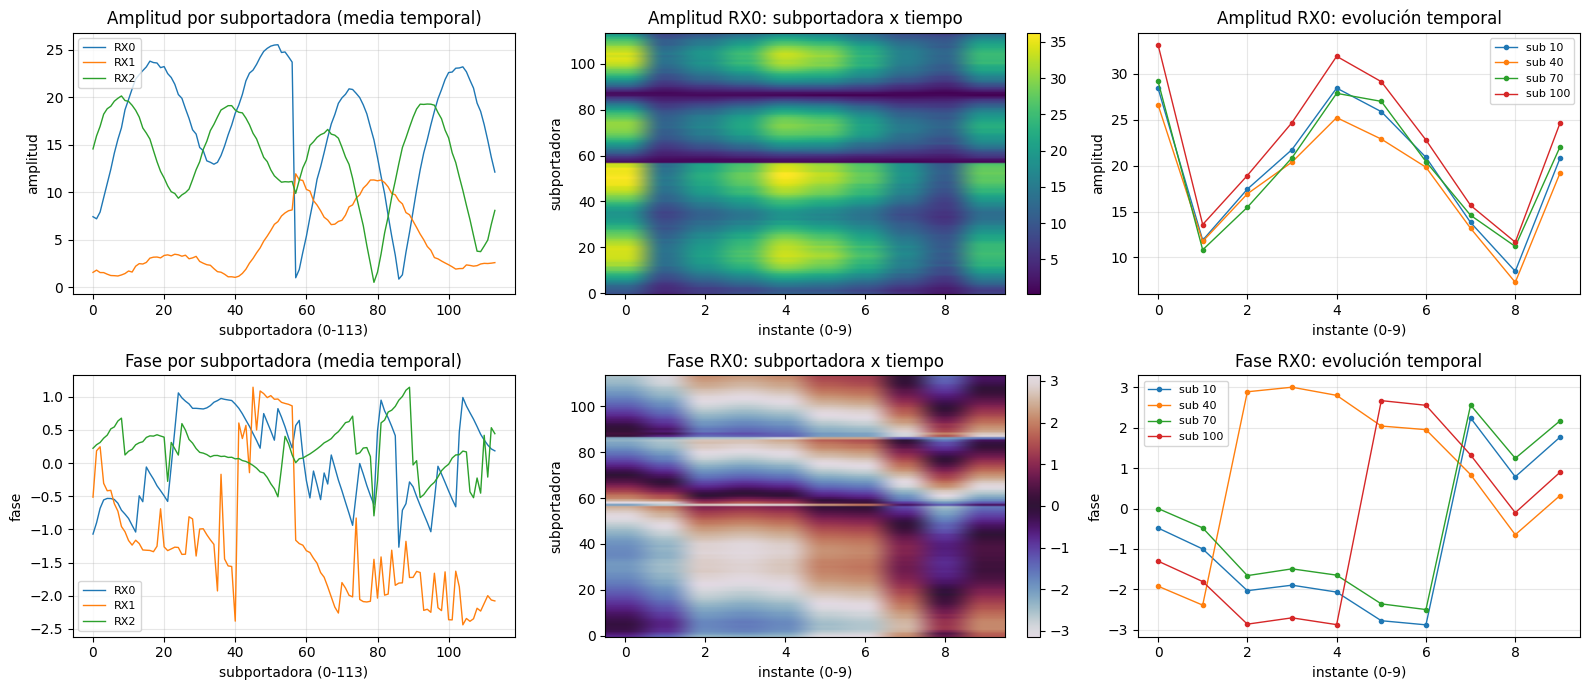


>> preprocesamiento_csi.png guardado


In [4]:
"""Inspección del preprocesamiento sobre un frame real (equivalente a la Fig. 1 del paper)."""
import scipy.io as scio

_m = scio.loadmat(ds.items[0][0])
_amp_raw = _m['CSIamp'].astype(np.float64)      # [3, 114, 10]
_pha_raw = _m['CSIphase'].astype(np.float64)

print(f'Frame: {os.path.basename(ds.items[0][0])}  (acción {ds.actions[0]})')
print(f'Shape : {_amp_raw.shape}  = [3 antenas, 114 subportadoras, 10 instantes]\n')
print(f'{"":14} | {"mín":>9} | {"máx":>9} | {"media":>9} | {"std":>8}')
print('-' * 60)
print(f'{"Amplitud cruda":14} | {_amp_raw.min():9.3f} | {_amp_raw.max():9.3f} | '
      f'{_amp_raw.mean():9.3f} | {_amp_raw.std():8.3f}')
print(f'{"Fase cruda":14} | {_pha_raw.min():9.3f} | {_pha_raw.max():9.3f} | '
      f'{_pha_raw.mean():9.3f} | {_pha_raw.std():8.3f}')

_a = (_amp_raw - _amp_raw.min()) / (_amp_raw.max() - _amp_raw.min() + 1e-9)
print(f'{"Amp min-max":14} | {_a.min():9.3f} | {_a.max():9.3f} | '
      f'{_a.mean():9.3f} | {_a.std():8.3f}   <- a [0,1]')
print(f'\nFase dentro de [-pi, pi]: '
      f'{"SÍ" if _pha_raw.min() >= -np.pi - 1e-6 and _pha_raw.max() <= np.pi + 1e-6 else "NO"}'
      f'   (pi = {np.pi:.3f})')

_x, _ = ds[0]
print(f'Tensor final  : {tuple(_x.shape)} | media {_x.mean():.4f} | std {_x.std():.4f}'
      f'   <- estandarizado')

# --- Gráficas: amplitud y fase sobre subportadoras y tiempo ---
fig, axes = plt.subplots(2, 3, figsize=(16, 7))

for fila, (M, nombre, cmap) in enumerate([(_amp_raw, 'Amplitud', 'viridis'),
                                          (_pha_raw, 'Fase', 'twilight')]):
    # Perfil por subportadora (las 3 antenas, promediado en tiempo)
    for ant in range(3):
        axes[fila, 0].plot(M[ant].mean(axis=1), lw=1, label=f'RX{ant}')
    axes[fila, 0].set_title(f'{nombre} por subportadora (media temporal)')
    axes[fila, 0].set_xlabel('subportadora (0-113)')
    axes[fila, 0].set_ylabel(nombre.lower())
    axes[fila, 0].legend(fontsize=8); axes[fila, 0].grid(alpha=0.3)

    # Mapa subportadora x tiempo (antena 0) — como la Fig. 1 del paper
    im = axes[fila, 1].imshow(M[0], aspect='auto', cmap=cmap, origin='lower')
    axes[fila, 1].set_title(f'{nombre} RX0: subportadora x tiempo')
    axes[fila, 1].set_xlabel('instante (0-9)'); axes[fila, 1].set_ylabel('subportadora')
    plt.colorbar(im, ax=axes[fila, 1], fraction=0.046)

    # Evolución temporal de algunas subportadoras
    for s in [10, 40, 70, 100]:
        axes[fila, 2].plot(M[0, s], marker='o', ms=3, lw=1, label=f'sub {s}')
    axes[fila, 2].set_title(f'{nombre} RX0: evolución temporal')
    axes[fila, 2].set_xlabel('instante (0-9)'); axes[fila, 2].set_ylabel(nombre.lower())
    axes[fila, 2].legend(fontsize=8); axes[fila, 2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT, 'preprocesamiento_csi.png'), dpi=120)
plt.show()
print('\n>> preprocesamiento_csi.png guardado')

## 4. Split 70/15/15 cronológico por acción

Dentro de cada acción los frames se ordenan por tiempo y se parten en bloques contiguos.
Esto evita la **fuga temporal**: con un split aleatorio, frames vecinos (casi idénticos a
~10 Hz) caerían en train y test a la vez, inflando las métricas.

In [5]:
def split_por_accion(ds, ratios):
    tr, va, te = [], [], []
    acts = np.array(ds.actions)
    for a in sorted(set(ds.actions)):
        idx = np.where(acts == a)[0]          # ya ordenados por nombre de frame = tiempo
        n = len(idx)
        n_tr = int(ratios[0] * n)
        n_va = int(ratios[1] * n)
        tr += idx[:n_tr].tolist()
        va += idx[n_tr:n_tr + n_va].tolist()
        te += idx[n_tr + n_va:].tolist()
    return tr, va, te


tr, va, te = split_por_accion(ds, CFG['split'])

# Con el dataset cacheado en RAM, num_workers=0 suele ser lo más rápido
# (no hay E/S que solapar y se evita el coste de crear procesos en Windows).
dl_kw = dict(batch_size=CFG['batch_size'],
             num_workers=0,
             pin_memory=CFG['pin_memory'])

train_dl = DataLoader(Subset(ds, tr), shuffle=True, drop_last=False, **dl_kw)
val_dl   = DataLoader(Subset(ds, va), shuffle=False, **dl_kw)

# Guardar el split para que la evaluación use exactamente el mismo test
json.dump({'ratios': list(CFG['split']), 'train': tr, 'val': va, 'test': te,
           'acciones': acciones},
          open(os.path.join(OUT, 'split.json'), 'w'))

print(f'train {len(tr)} | val {len(va)} | test {len(te)}  (total {len(ds)})')
print(f'batches por época: {len(train_dl)} train | {len(val_dl)} val  (batch={CFG["batch_size"]})')
print(f'>> split.json guardado en {OUT}')

train 492 | val 102 | test 112  (total 706)
batches por época: 21 train | 5 val  (batch=24)
>> split.json guardado en C:\Users\Adrian\Desktop\New folder\tesis-csi2pc-wifi\pc\resultados


## 5. Modelo, optimizador, scheduler y pérdida

- **Optimizador:** NAdam, lr = 1e-4 (igual en paper y código)
- **Scheduler:** `StepLR(step_size=10, gamma=0.5)` — del paper §IV-D. Baja el learning rate
  a la mitad cada 10 épocas, de modo que al final del entrenamiento sea 1/32 del inicial.
  Sirve para afinar: pasos grandes al principio, pequeños al converger.
- **Pérdida:** `CSI2PointCloudLoss(0.85, 0.15)` = `0.85 · Chamfer + 0.15 · reg`, la ec. (4)
  del paper con los pesos que usa el entrenamiento oficial.

In [6]:
model = CSI2PointCloudModel(
    embedding_dim=CFG['embedding_dim'],
    num_heads=CFG['num_heads'],
    num_encoder_layers=CFG['num_encoder_layers'],
    num_decoder_layers=CFG['num_decoder_layers'],
    num_points=CFG['num_points'],
    num_antennas=CFG['num_antennas'],
    num_subcarriers=CFG['num_subcarriers'],
    num_time_slices=CFG['num_time_slices'],
).to(device)

optimizer = torch.optim.NAdam(model.parameters(), lr=CFG['lr'])
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer, step_size=CFG['sched_step'], gamma=CFG['sched_gamma'])
loss_fn = CSI2PointCloudLoss(
    chamfer_weight=CFG['chamfer_weight'],
    regularization_weight=CFG['regularization_weight'])

n_params = sum(p.numel() for p in model.parameters())
print('[Modelo]')
print(f'  Embedding dim    : {model.embedding_dim}')
print(f'  Heads            : {model.num_heads}')
print(f'  Puntos de salida : {model.num_points}')
print(f'  Antenas          : {model.num_antennas}')
print(f'  Subportadoras    : {model.num_subcarriers}')
print(f'  Parámetros       : {n_params:,}')

[Modelo]
  Embedding dim    : 256
  Heads            : 4
  Puntos de salida : 1200
  Antenas          : 3
  Subportadoras    : 114
  Parámetros       : 9,086,979


## 6. Bucle de entrenamiento

Guarda el mejor modelo según la pérdida de **validación** (no la de train).

In [7]:
from torch.amp import autocast, GradScaler

usar_amp = CFG['amp'] and device.type == 'cuda'
scaler = GradScaler('cuda', enabled=usar_amp)


def train_epoch(model, dl):
    model.train()
    losses = []
    for x, g in dl:
        x = x.to(device, non_blocking=True)
        g = g.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with autocast('cuda', enabled=usar_amp):
            pred, trans_feat = model(x)
            loss = loss_fn(pred, g, trans_feat)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        losses.append(loss.item())
    return float(np.mean(losses))


@torch.no_grad()
def eval_epoch(model, dl):
    model.eval()
    losses = []
    for x, g in dl:
        x = x.to(device, non_blocking=True)
        g = g.to(device, non_blocking=True)
        with autocast('cuda', enabled=usar_amp):
            pred, trans_feat = model(x)
            loss = loss_fn(pred, g, trans_feat)
        losses.append(loss.item())
    return float(np.mean(losses)) if losses else float('nan')


hist = {'train': [], 'val': [], 'lr': []}
best = None
ckpt_path = os.path.join(OUT, 'modelo', 'csi2pc_v2.pth')
t0 = time.time()

print(f'Entrenando {CFG["epochs"]} épocas en {device} '
      f'(AMP {"ON" if usar_amp else "OFF"}, batch {CFG["batch_size"]})\n')

for ep in range(CFG['epochs']):
    t1 = time.time()
    tl = train_epoch(model, train_dl)
    scheduler.step()
    vl = eval_epoch(model, val_dl)
    lr_actual = optimizer.param_groups[0]['lr']

    hist['train'].append(tl)
    hist['val'].append(vl)
    hist['lr'].append(lr_actual)

    marca = ''
    if best is None or vl < best:
        best = vl
        torch.save({'model_state_dict': model.state_dict(),
                    'epochs': ep + 1,
                    'config': CFG,
                    'val_loss': vl}, ckpt_path)
        marca = '  <-- mejor'

    print(f'Época {ep+1:3d}/{CFG["epochs"]} | train {tl:9.4f} | val {vl:9.4f} | '
          f'lr {lr_actual:.2e} | {time.time()-t1:5.1f}s{marca}', flush=True)

print(f'\nTiempo total: {(time.time()-t0)/60:.1f} min')
print(f'Mejor val loss: {best:.4f}')
print(f'Modelo guardado: {ckpt_path}')

Entrenando 50 épocas en cuda (AMP ON, batch 24)



Época   1/50 | train 3596.6808 | val 1673.5229 | lr 1.00e-04 |   2.4s  <-- mejor


Época   2/50 | train 1472.2262 | val 1425.4685 | lr 1.00e-04 |   1.9s  <-- mejor


Época   3/50 | train 1345.7615 | val 1339.6807 | lr 1.00e-04 |   1.9s  <-- mejor


Época   4/50 | train 1278.9864 | val 1285.7237 | lr 1.00e-04 |   1.9s  <-- mejor


...

Época  47/50 | train 1028.4086 | val 1031.9652 | lr 6.25e-06 |   1.9s  <-- mejor


Época  48/50 | train 1027.2286 | val 1030.5144 | lr 6.25e-06 |   1.9s  <-- mejor


Época  49/50 | train 1026.2531 | val 1029.0670 | lr 6.25e-06 |   1.9s  <-- mejor


Época  50/50 | train 1025.2473 | val 1027.5983 | lr 3.13e-06 |   1.9s  <-- mejor



Tiempo total: 1.6 min
Mejor val loss: 1027.5983
Modelo guardado: C:\Users\Adrian\Desktop\New folder\tesis-csi2pc-wifi\pc\resultados\modelo\csi2pc_v2.pth


## 7. Curva de pérdida

Train y val deben bajar juntas. Si val se separa y sube mientras train baja → **overfitting**
(probable con ~700 pares: baja épocas o activa data augmentation).

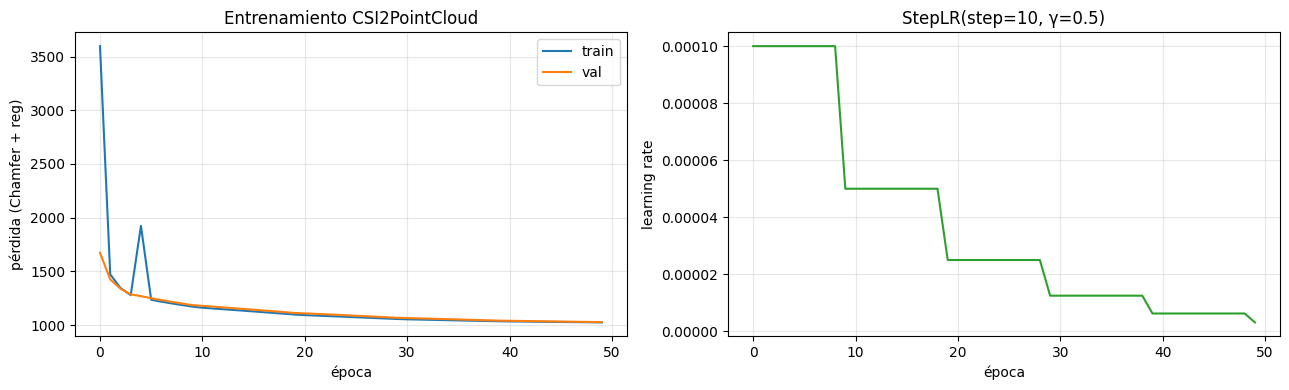

>> curva_perdida.png e historial.json guardados


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.plot(hist['train'], label='train')
ax1.plot(hist['val'], label='val')
ax1.set_xlabel('época'); ax1.set_ylabel('pérdida (Chamfer + reg)')
ax1.set_title('Entrenamiento CSI2PointCloud'); ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(hist['lr'], color='tab:green')
ax2.set_xlabel('época'); ax2.set_ylabel('learning rate')
ax2.set_title(f'StepLR(step={CFG["sched_step"]}, γ={CFG["sched_gamma"]})')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT, 'curva_perdida.png'), dpi=120)
plt.show()

json.dump(hist, open(os.path.join(OUT, 'historial.json'), 'w'))
print('>> curva_perdida.png e historial.json guardados')

## 8. Visualización GT vs predicho

Colores de Määttä: colormap `viridis` según distancia al sensor.

Checkpoint: época 50 | val loss 1027.5983


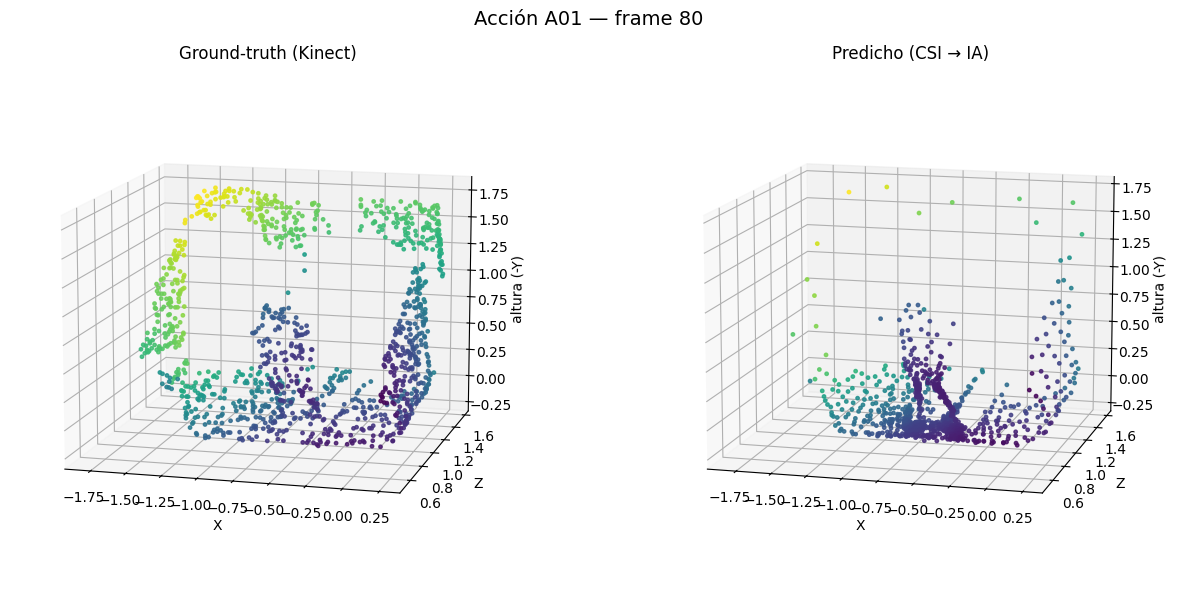

>> pred_vs_gt.png guardado


In [9]:
def plot_nube(ax, P, titulo, cmap='viridis'):
    """Orientación de pie: (X, Z, -Y). Color = distancia al sensor."""
    h, prof, alt = P[:, 0], P[:, 2], -P[:, 1]
    dist = np.linalg.norm(P, axis=1)
    sc = ax.scatter(h, prof, alt, c=dist, cmap=cmap, s=6, alpha=0.85)
    ax.set_title(titulo, fontsize=12)
    ax.set_xlabel('X'); ax.set_ylabel('Z'); ax.set_zlabel('altura (-Y)')
    ax.view_init(elev=12, azim=-75)
    return sc


# Cargar el mejor checkpoint (el de menor pérdida de validación)
ck = torch.load(ckpt_path, map_location=device, weights_only=False)
model.load_state_dict(ck['model_state_dict'])
model.eval()
print(f'Checkpoint: época {ck["epochs"]} | val loss {ck["val_loss"]:.4f}')

# Un frame del conjunto de validación
i_vis = va[0] if va else 0
x, g = ds[i_vis]
with torch.no_grad():
    pred, _ = model(x.unsqueeze(0).to(device))
pred = pred.squeeze(0).float().cpu().numpy()
gt = g.numpy()

fig = plt.figure(figsize=(13, 6))
fig.suptitle(f'Acción {ds.actions[i_vis]} — frame {i_vis}', fontsize=14)
plot_nube(fig.add_subplot(1, 2, 1, projection='3d'), gt,   'Ground-truth (Kinect)')
plot_nube(fig.add_subplot(1, 2, 2, projection='3d'), pred, 'Predicho (CSI → IA)')
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'pred_vs_gt.png'), dpi=120)
plt.show()

print('>> pred_vs_gt.png guardado')

## 9. Métricas ICP sobre el test reservado

El **test** es el último 15 % cronológico de cada acción: el modelo nunca lo vio.

- **ICP fitness** — fracción de puntos con correspondencia dentro del umbral
- **ICP RMSE** — error de esas correspondencias (metros)
- **Chamfer** — distancia bidireccional media

Se reporta a varios umbrales porque el paper (Tabla I) obtiene RMSE ≈ 0.0103 m, un orden de
magnitud por debajo del umbral de 0.10 m; sin eso la comparación no sería informativa.

> **Atención:** las cifras del paper (fitness 0.6358) **no son directamente comparables** con
> estas. Määttä evalúa con split por sujeto / por sala sobre MM-Fi, con LiDAR Ouster como GT
> y escenas completas (persona + muebles + sala). Aquí es 1 sujeto, Kinect, y split temporal.

In [10]:
import open3d as o3d

UMBRALES = [0.01, 0.05, 0.10]


def nube(P):
    """PointCloud de Open3D desde un array (requiere float64 y escribible)."""
    return o3d.geometry.PointCloud(
        o3d.utility.Vector3dVector(np.ascontiguousarray(P, dtype=np.float64)))


def nn_dist(A, B):
    kdt = o3d.geometry.KDTreeFlann(nube(B))
    d = np.empty(len(A))
    for i, p in enumerate(A):
        _, _, d2 = kdt.search_knn_vector_3d(p, 1)
        d[i] = np.sqrt(d2[0])
    return d


# --- Predicciones sobre el test, por lotes en GPU (una sola pasada) ---
t0 = time.time()
test_dl = DataLoader(Subset(ds, te), batch_size=CFG['batch_size'], shuffle=False)

preds_norm = []
model.eval()
with torch.no_grad():
    for x, _ in test_dl:
        p, _ = model(x.to(device, non_blocking=True))
        preds_norm.append(p.float().cpu().numpy().astype(np.float64))
preds_norm = np.concatenate(preds_norm, axis=0)

# Desnormalizar cada predicción a metros con la escala de su propio GT
# (.copy() porque np.frombuffer devuelve un array de solo lectura y Open3D
#  necesita poder escribir en él)
preds_m, gts, acts_test = [], [], []
for k, i in enumerate(te):
    gt_raw = np.frombuffer(open(ds.items[i][1], 'rb').read(),
                           dtype=np.float64).reshape(-1, 3).copy()
    preds_m.append(preds_norm[k] * gt_raw.std() + gt_raw.mean())
    gts.append(gt_raw)
    acts_test.append(ds.actions[i])

print(f'Frames de test evaluados: {len(preds_m)}  (inferencia: {time.time()-t0:.1f}s)\n')

lineas = []
for THR in UMBRALES:
    fits, rmses, chamfs = [], [], []
    por_accion = {}
    for pm, gt, a in zip(preds_m, gts, acts_test):
        reg = o3d.pipelines.registration.registration_icp(
            nube(pm), nube(gt), THR, np.eye(4),
            o3d.pipelines.registration.TransformationEstimationPointToPoint())
        ch = nn_dist(pm, gt).mean() + nn_dist(gt, pm).mean()
        fits.append(reg.fitness); rmses.append(reg.inlier_rmse); chamfs.append(ch)
        por_accion.setdefault(a, []).append((reg.fitness, reg.inlier_rmse, ch))

    cab = f'=== Umbral {THR:.2f} m ==='
    print(cab)
    print(f'  ICP fitness : {np.mean(fits):.4f}')
    print(f'  ICP RMSE    : {np.mean(rmses):.4f} m')
    print(f'  Chamfer     : {np.mean(chamfs):.4f} m')
    lineas += [cab,
               f'  ICP fitness : {np.mean(fits):.4f}',
               f'  ICP RMSE    : {np.mean(rmses):.4f} m',
               f'  Chamfer     : {np.mean(chamfs):.4f} m',
               '  Por acción:']
    for a in sorted(por_accion):
        v = np.array(por_accion[a])
        ln = (f'    {a} | fitness {v[:,0].mean():.3f} | RMSE {v[:,1].mean():.4f} m | '
              f'Chamfer {v[:,2].mean():.4f} m | n={len(v)}')
        print(ln); lineas.append(ln)
    print()
    lineas.append('')

ref = ('Referencia paper (Tabla I, NO comparable directamente — MM-Fi, LiDAR, split por sujeto):\n'
       '  Subject-based: ICP Fitness 0.6358 | RMSE 0.0103 m\n'
       '  Room-based   : ICP Fitness 0.6127 | RMSE 0.0104 m')
print(ref)

with open(os.path.join(OUT, 'metricas_test.txt'), 'w', encoding='utf-8') as f:
    f.write(f'TEST: {len(preds_m)} frames | preset {PRESET} | {CFG["epochs"]} épocas\n\n')
    f.write('\n'.join(lineas))
    f.write('\n' + ref + '\n')

print(f'\n>> metricas_test.txt guardado en {OUT}')

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Frames de test evaluados: 112  (inferencia: 0.4s)



=== Umbral 0.01 m ===
  ICP fitness : 0.0260
  ICP RMSE    : 0.0070 m
  Chamfer     : 0.1333 m
    A01 | fitness 0.026 | RMSE 0.0070 m | Chamfer 0.1328 m | n=18
    A02 | fitness 0.025 | RMSE 0.0070 m | Chamfer 0.1198 m | n=20
    A03 | fitness 0.023 | RMSE 0.0070 m | Chamfer 0.1374 m | n=18
    A04 | fitness 0.027 | RMSE 0.0071 m | Chamfer 0.1498 m | n=19
    A05 | fitness 0.029 | RMSE 0.0071 m | Chamfer 0.1260 m | n=19
    A06 | fitness 0.025 | RMSE 0.0069 m | Chamfer 0.1349 m | n=18



=== Umbral 0.05 m ===
  ICP fitness : 0.8041
  ICP RMSE    : 0.0311 m
  Chamfer     : 0.1333 m
    A01 | fitness 0.824 | RMSE 0.0310 m | Chamfer 0.1328 m | n=18
    A02 | fitness 0.848 | RMSE 0.0313 m | Chamfer 0.1198 m | n=20
    A03 | fitness 0.730 | RMSE 0.0317 m | Chamfer 0.1374 m | n=18
    A04 | fitness 0.782 | RMSE 0.0309 m | Chamfer 0.1498 m | n=19
    A05 | fitness 0.839 | RMSE 0.0310 m | Chamfer 0.1260 m | n=19
    A06 | fitness 0.796 | RMSE 0.0310 m | Chamfer 0.1349 m | n=18



=== Umbral 0.10 m ===
  ICP fitness : 0.9826
  ICP RMSE    : 0.0385 m
  Chamfer     : 0.1333 m
    A01 | fitness 0.989 | RMSE 0.0379 m | Chamfer 0.1328 m | n=18
    A02 | fitness 0.996 | RMSE 0.0373 m | Chamfer 0.1198 m | n=20
    A03 | fitness 0.987 | RMSE 0.0412 m | Chamfer 0.1374 m | n=18
    A04 | fitness 0.971 | RMSE 0.0390 m | Chamfer 0.1498 m | n=19
    A05 | fitness 0.991 | RMSE 0.0375 m | Chamfer 0.1260 m | n=19
    A06 | fitness 0.960 | RMSE 0.0384 m | Chamfer 0.1349 m | n=18

Referencia paper (Tabla I, NO comparable directamente — MM-Fi, LiDAR, split por sujeto):
  Subject-based: ICP Fitness 0.6358 | RMSE 0.0103 m
  Room-based   : ICP Fitness 0.6127 | RMSE 0.0104 m

>> metricas_test.txt guardado en C:\Users\Adrian\Desktop\New folder\tesis-csi2pc-wifi\pc\resultados


## 10. Resumen

Archivos generados en la carpeta de resultados:

| Archivo | Contenido |
|---|---|
| `modelo/csi2pc_v2.pth` | mejor modelo según validación |
| `curva_perdida.png` | pérdida train/val + learning rate |
| `pred_vs_gt.png` | nube real vs predicha |
| `metricas_test.txt` | ICP fitness, RMSE y Chamfer a 3 umbrales |
| `split.json` | índices exactos de train/val/test |
| `historial.json` | pérdidas por época |

In [11]:
print('Resultados en:', OUT)
for f in sorted(os.listdir(OUT)):
    ruta = os.path.join(OUT, f)
    if os.path.isfile(ruta):
        print(f'  {f:24s} {os.path.getsize(ruta)/1024:8.1f} KB')
    else:
        print(f'  {f}/')

Resultados en: C:\Users\Adrian\Desktop\New folder\tesis-csi2pc-wifi\pc\resultados
  curva_perdida.png            51.9 KB
  eda_1_espectro.png          494.9 KB
  eda_1b_subportadoras.png     86.7 KB
  eda_2_receptores.png        105.3 KB
  eda_3_variabilidad.png       33.7 KB
  eda_4_separabilidad.png      43.0 KB
  eda_senal.txt                 3.5 KB
  gif_A01.gif                 525.4 KB
  gif_A02.gif                 539.5 KB
  gif_A03.gif                 472.9 KB
  gif_A04.gif                 523.4 KB
  gif_A05.gif                 539.5 KB
  gif_A06.gif                 510.7 KB
  historial.json                2.4 KB
  metricas_test.json            1.4 KB
  metricas_test.png            61.6 KB
  metricas_test.txt             1.8 KB
  modelo/
  pred_vs_gt.png              259.2 KB
  preprocesamiento_csi.png    497.4 KB
  split.json                    3.5 KB
  test_todas_acciones.png    1010.4 KB
  video_test_A04.gif          526.2 KB
  video_test_A04.mp4          797.2 KB
  video_tes